# Module 4 · Notebook 2: The experiment

**Question: how much faster does generation get with a KV cache, and how much memory does the cache cost as the context grows?**

Notebook 1 proved the cache gives exactly the same model and is ~9× faster at the full 128 characters. 128 is too short to see how things *grow*, and the trained model has no position 129. So the long contexts here use **the same architecture with random weights** and a longer position table. The text it writes would be nonsense, but the work per token (the number and size of the matrix multiplications) and the memory don't depend on what the weights are. Step 1 checks that.

| Step | What we do | Runtime |
|---|---|---|
| 1 | Do the weights affect the speed? Trained vs random, same contexts | ~10 s |
| 2 | Is the cache still exact at a long context? | ~5 s |
| 3 | Time per new token, from 16 to 2,048 positions (16,384 with the cache) | ~1–2 min |
| 4 | Why the curves look like that: counting the multiplications | — |
| 5 | Total time to write 512 tokens from scratch | ~30 s |
| 6 | Memory: the cache, and what the uncached forward needs | ~10 s |
| 7 | What this means for real models (calculated, not measured) | — |

**Runtime:** about 2–3 minutes on a laptop CPU.

In [1]:
import sys, time, math, tracemalloc
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

LAB = Path.cwd().resolve().parents[1]
sys.path.insert(0, str(LAB / "03-gpt"))
from gpt import load_checkpoint, init_gpt

print("python", sys.version.split()[0], "| numpy", np.__version__)

SURFACE, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "text.color": INK, "axes.titlecolor": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.6, "axes.spines.top": False, "axes.spines.right": False,
    "lines.linewidth": 2, "font.size": 10, "legend.frameon": False,
})

python 3.12.15 | numpy 2.5.3


The forward passes from notebook 1, unchanged except that they take the config as an argument, so the same code runs the trained model (128 positions) and the longer random ones.

In [2]:
def layer_norm(x, g, b, eps=1e-5):
    xc = x - x.mean(-1, keepdims=True)
    return xc * ((xc**2).mean(-1, keepdims=True) + eps)**-0.5 * g + b

def gelu(x):
    return 0.5 * x * (1 + np.tanh(math.sqrt(2 / math.pi) * (x + 0.044715 * x**3)))

def softmax(z):
    e = np.exp(z - z.max(-1, keepdims=True))
    return e / e.sum(-1, keepdims=True)

def forward(p, idx, cfg):
    # the whole sequence, every time
    B, T = idx.shape
    L, H, C = cfg["L"], cfg["H"], cfg["C"]
    heads = lambda a: a.reshape(B, -1, H, C // H).transpose(0, 2, 1, 3)
    x = p["wte"][idx] + p["wpe"][:T]
    mask = np.triu(np.full((T, T), -np.inf), k=1)
    for i in range(L):
        g = lambda k: p[f"h{i}.{k}"]
        h = layer_norm(x, g("ln1_g"), g("ln1_b"))
        q, k, v = heads(h @ g("Wq")), heads(h @ g("Wk")), heads(h @ g("Wv"))
        a = softmax(q @ k.transpose(0, 1, 3, 2) / math.sqrt(C // H) + mask)
        x = x + (a @ v).transpose(0, 2, 1, 3).reshape(B, T, C) @ g("Wo")
        h = layer_norm(x, g("ln2_g"), g("ln2_b"))
        x = x + gelu(h @ g("W1") + g("b1")) @ g("W2") + g("b2")
    return layer_norm(x, p["lnf_g"], p["lnf_b"]) @ p["wte"].T

def new_cache(cfg, B=1):
    shape = (cfg["L"], B, cfg["H"], cfg["T"], cfg["C"] // cfg["H"])
    return {"k": np.zeros(shape), "v": np.zeros(shape), "n": 0}

def forward_cached(p, idx, cache, cfg):
    # only the new tokens: append their keys/values, attend over the whole cache
    B, t = idx.shape
    n = cache["n"]
    L, H, C = cfg["L"], cfg["H"], cfg["C"]
    heads = lambda a: a.reshape(B, -1, H, C // H).transpose(0, 2, 1, 3)
    x = p["wte"][idx] + p["wpe"][n:n + t]
    mask = np.triu(np.full((t, n + t), -np.inf), k=n + 1)
    for i in range(L):
        g = lambda k: p[f"h{i}.{k}"]
        h = layer_norm(x, g("ln1_g"), g("ln1_b"))
        q = heads(h @ g("Wq"))
        cache["k"][i, :, :, n:n + t] = heads(h @ g("Wk"))
        cache["v"][i, :, :, n:n + t] = heads(h @ g("Wv"))
        K, Vv = cache["k"][i, :, :, :n + t], cache["v"][i, :, :, :n + t]
        a = softmax(q @ K.transpose(0, 1, 3, 2) / math.sqrt(C // H) + mask)
        x = x + (a @ Vv).transpose(0, 2, 1, 3).reshape(B, t, C) @ g("Wo")
        h = layer_norm(x, g("ln2_g"), g("ln2_b"))
        x = x + gelu(h @ g("W1") + g("b1")) @ g("W2") + g("b2")
    cache["n"] = n + t
    return layer_norm(x, p["lnf_g"], p["lnf_b"]) @ p["wte"].T

def prefill(p, ids, cache, cfg, chunk=256):
    # fill the cache a chunk at a time. in one go, a 16k prompt would build a 16k x 16k
    # attention matrix per head (~8.6 GB in float64); chunks of 256 keep it to 256 x 16k
    for s in range(0, ids.shape[1], chunk):
        out = forward_cached(p, ids[:, s:s + chunk], cache, cfg)
    return out

def best_time(f, repeats=5):
    # timings on a laptop jump around, so take the fastest of a few
    best = float("inf")
    for _ in range(repeats):
        t0 = time.perf_counter()
        f()
        best = min(best, time.perf_counter() - t0)
    return best

def time_uncached(p, cfg, ids, t, repeats=5):
    return best_time(lambda: forward(p, ids[:, :t], cfg), repeats)

def time_cached(p, cfg, ids, t, repeats=5):
    # fill the cache with t-1 tokens once, then time decoding the t-th one
    cache = new_cache(cfg)
    prefill(p, ids[:, :t - 1], cache, cfg)
    def step():
        cache["n"] = t - 1
        forward_cached(p, ids[:, t - 1:t], cache, cfg)
    return best_time(step, repeats)

trained, cfg128, tok, info = load_checkpoint(LAB / "03-gpt" / "checkpoints" / "gpt.npz")
print(f"trained model: step {info['step']}, val {info['val']:.3f}, config {cfg128}")

trained model: step 2250, val 1.417, config {'T': 128, 'C': 128, 'L': 4, 'H': 4, 'V': 88}


## Step 1: Do the weights affect the speed?

If the random-weight model is going to stand in for the trained one, the two must take the same time at the same context. Same architecture, same contexts (up to the trained model's 128), timed alternately so that both see the same state of the laptop.

In [3]:
random128 = init_gpt(cfg128, np.random.default_rng(0))      # same shapes, random weights (the init from Module 3)
ids = np.random.default_rng(1).integers(0, cfg128["V"], (1, 128))

print(f"{'context':>8s} {'':12s} {'trained':>9s} {'random':>9s}  ratio")
for t in (16, 64, 128):
    for name, timer in (("uncached", time_uncached), ("cached", time_cached)):
        a = b = float("inf")
        for _ in range(3):                                   # alternate, so neither gets a lucky moment
            a = min(a, timer(trained, cfg128, ids, t, 3))
            b = min(b, timer(random128, cfg128, ids, t, 3))
        print(f"{t:8d} {name:12s} {a * 1e3:7.2f}ms {b * 1e3:7.2f}ms  {b / a:5.2f}")

 context                trained    random  ratio
      16 uncached        3.77ms    3.88ms   1.03
      16 cached          1.75ms    1.58ms   0.90
      64 uncached        9.50ms   10.57ms   1.11
      64 cached          1.50ms    1.60ms   1.07
     128 uncached       19.50ms   22.15ms   1.14
     128 cached          1.46ms    1.50ms   1.03


Trained and random take the same time: the ratios stay close to 1 (0.96–1.11 in one of my runs, 0.90–1.14 in another), about as much as these timings move from one run to the next anyway. NumPy does the same multiplications whatever the numbers are, so the random model is a fair stand-in for speed and memory.

## Step 2: Is the cache still exact at a long context?

Notebook 1 proved cached = uncached for the trained model up to 128. Here the same check on the random model with a 2,048-position table, at a context of 1,500: prefill 1,499 tokens, decode the 1,500th, compare with a full forward pass.

From here on the prompt is prefilled **in chunks** of 256 tokens. The first version of this notebook prefilled 16,384 tokens in one call, which builds a 16k × 16k attention matrix per head (~8.6 GB) and took minutes. Real inference servers do chunked prefill for the same reason. It gives the same cache, because each chunk only attends to what is already cached plus itself.

In [4]:
cfg2k = dict(cfg128, T=2048)
model2k = init_gpt(cfg2k, np.random.default_rng(0))
ids2k = np.random.default_rng(2).integers(0, cfg2k["V"], (1, 2048))

full = forward(model2k, ids2k[:, :1500], cfg2k)[0, -1]
cache = new_cache(cfg2k)
prefill(model2k, ids2k[:, :1499], cache, cfg2k)
decoded = forward_cached(model2k, ids2k[:, 1499:1500], cache, cfg2k)[0, -1]
print(f"context 1500: max |cached - uncached| on the logits = {np.abs(full - decoded).max():.1e}")

context 1500: max |cached - uncached| on the logits = 1.2e-15


Still exact to rounding error.

## Step 3: Time per new token

The main measurement: how long one new token takes, at a context of $t$ tokens. Without the cache that is a full forward pass over $t$ positions. With the cache, it is one decode step after $t-1$ cached positions.

Without the cache it stops at 2,048 (a 4,096 context would need ~0.5 GB for each attention-score matrix, see Step 6). With the cache it goes on to 16,384, to see whether it stays flat.

In [5]:
cfg16k = dict(cfg128, T=16384)
model16k = init_gpt(cfg16k, np.random.default_rng(0))
ids16k = np.random.default_rng(3).integers(0, cfg16k["V"], (1, 16384))

CTX = [16, 32, 64, 128, 256, 512, 1024, 2048]
CTX_CACHED = CTX + [4096, 8192, 16384]

t_unc = {t: time_uncached(model2k, cfg2k, ids2k, t, 3 if t >= 1024 else 5) for t in CTX}
t_cac = {t: time_cached(model16k, cfg16k, ids16k, t, 7) for t in CTX_CACHED}

print(f"{'context':>8s} {'without cache':>14s} {'with cache':>11s} {'speedup':>8s}")
for t in CTX_CACHED:
    u = f"{t_unc[t] * 1e3:11.1f} ms" if t in t_unc else f"{'-':>14s}"
    s = f"{t_unc[t] / t_cac[t]:7.0f}x" if t in t_unc else ""
    print(f"{t:8d} {u} {t_cac[t] * 1e3:8.2f} ms {s}")

 context  without cache  with cache  speedup
      16         4.3 ms     1.33 ms       3x
      32         6.3 ms     1.29 ms       5x
      64        10.6 ms     1.33 ms       8x
     128        23.7 ms     1.51 ms      16x
     256        64.4 ms     0.81 ms      80x
     512       185.2 ms     1.74 ms     106x
    1024       558.9 ms     1.59 ms     352x
    2048      1631.8 ms     2.67 ms     612x
    4096              -     4.75 ms 
    8192              -     8.64 ms 
   16384              -    16.31 ms 


Without the cache, the time per token goes from a few ms at 16 tokens to ~1.5 s at 2,048: 128× the context, roughly 400–550× the time. With the cache it stays roughly flat, ~1–1.5 ms, up to ~512 tokens, and only then starts to grow: ~2–3 ms at 2,048, ~11–16 ms at 16,384. At 2,048 that is roughly 600–750× faster than this forward. Against a fairer one that does attention in blocks of query rows (same logits, less memory, see Step 6), `run.py` measures ~430–510×.

(These ranges come from two runs on the same laptop. Single points jump around, like a cached step that came out faster at 256 than at 128 in one run. The shape is stable, the third digit isn't.)

## Step 4: Why the curves look like that

Count the multiply-adds per new token. Per layer and per position: the four attention projections ($q, k, v$ and the output) are $4C^2$, the MLP is $8C^2$, so $12C^2$. Attention itself: a query at position $t$ against $t$ keys is $tC$ for the scores and $tC$ for the weighted sum of values.

| | multiply-adds per new token at context $t$ |
|---|---|
| without cache | $L\,(12C^2\,t + C\,t^2) + VC\,t$ (every position again, and attention over all pairs) |
| with cache | $L\,(12C^2 + 2C\,t) + VC$ (one position, attending over $t$ cached ones) |

So without the cache the cost grows like $t^2$ once attention dominates; with it, like $t$. And with the cache, attention ($2Ct$) only becomes as big as everything else ($12C^2$) at $t = 6C = 768$ for this model. Below that a cached step is basically constant work; above it, it grows linearly.

In [6]:
L_, C_, V_ = cfg128["L"], cfg128["C"], cfg128["V"]
flops_unc = lambda t: L_ * (12 * C_**2 * t + C_ * t**2) + V_ * C_ * t
flops_cac = lambda t: L_ * (12 * C_**2 + 2 * C_ * t) + V_ * C_

print(f"{'context':>8s} {'multiply-adds':>16s} {'':>12s} {'ratio':>7s} | {'measured speedup':>16s}")
print(f"{'':8s} {'without cache':>16s} {'with cache':>12s}")
for t in CTX:
    print(f"{t:8d} {flops_unc(t):16,.0f} {flops_cac(t):12,.0f} {flops_unc(t) / flops_cac(t):6.0f}x | {t_unc[t] / t_cac[t]:15.0f}x")

 context    multiply-adds                ratio | measured speedup
            without cache   with cache
      16       12,894,208      814,080     16x |               3x
      32       26,050,560      830,464     31x |               5x
      64       53,149,696      863,232     62x |               8x
     128      110,493,696      928,768    119x |              16x
     256      237,764,608    1,059,840    224x |              80x
     512      542,638,080    1,321,984    410x |             106x
    1024    1,353,711,616    1,846,272    733x |             352x
    2048    3,781,165,056    2,894,848   1306x |             612x


Three things in this table:

- **The measured speedup is always smaller than the count says**, most at short contexts (3–4× measured against 16× counted at 16 tokens). A cached step has a fixed cost of ~1 ms of Python and NumPy overhead, dozens of small array operations, that the count ignores. So at short contexts the cache can't show its full saving.
- **The cached curve bends where the count predicts**: roughly flat until ~512, then close to linear, since $t = 6C = 768$ is where attention's multiply-adds catch up with the rest of the step. In measured time attention is still small there (~0.3 ms on top of ~0.7 ms of overhead at 768), so the bend is gentle. From 2,048 to 16,384 is 8× the context and ~5–6× the time.
- **The uncached time grows faster than its count** (~400–550× against ~290× from 16 to 2,048 tokens). The $t^2$ part isn't only multiply-adds: there is also the softmax's `exp` and the mask over all $t^2$ scores, and half a gigabyte of them going through memory (Step 6). It isn't fully quadratic yet, though: from 1,024 to 2,048 the time goes up ~3× for the doubling, on its way to 4×.

## Step 5: Total time to write 512 tokens

The per-token numbers add up. Writing $N$ tokens from scratch without a cache costs the sum over every context from 1 to $N$, so it grows like $N^3$ once attention dominates (like $N^2$ before that). With the cache it grows like $N^2$ at worst. A real measurement, 512 tokens with the random 2k model, greedy:

In [7]:
def write_uncached(n):
    ids = [0]
    for _ in range(n):
        ids.append(int(np.argmax(forward(model2k, np.array(ids)[None], cfg2k)[0, -1])))
    return ids

def write_cached(n):
    ids = [0]
    cache = new_cache(cfg2k)
    logits = forward_cached(model2k, np.array([ids]), cache, cfg2k)[0, -1]
    for _ in range(n):
        ids.append(int(np.argmax(logits)))
        logits = forward_cached(model2k, np.array([[ids[-1]]]), cache, cfg2k)[0, -1]
    return ids

t0 = time.perf_counter(); a = write_uncached(512); total_unc = time.perf_counter() - t0
t0 = time.perf_counter(); b = write_cached(512); total_cac = time.perf_counter() - t0
print(f"512 tokens: {total_unc:.1f} s without cache, {total_cac:.2f} s with ({total_unc / total_cac:.0f}x), same tokens: {a == b}")

512 tokens: 33.7 s without cache, 0.72 s with (47x), same tokens: True


~32–34 s against ~0.45–0.7 s: about 50–70× for 512 tokens, and exactly the same tokens. That's less than the per-token speedup at 512 (~105–110×), because the total averages over all the short contexts on the way, where the cache saves less.

## Step 6: Memory

Two different memory costs:

- **the cache** is kept for as long as the sequence is being generated: $2 \times L \times t \times C$ numbers, growing linearly with the context;
- **without the cache**, nothing is kept between steps, but every step builds the attention scores for all $t \times t$ pairs (per head and per layer, though only one layer at a time is alive). That is temporary, and grows with $t^2$. (That's how this forward is written. Step 6's result below explains why it isn't the whole story.)

`tracemalloc` measures the peak memory NumPy allocates during one step, so both can be compared directly. The line for the model's own weights (6.55 MB) shows where the cache gets bigger than the model.

In [8]:
def peak_mb(f):
    tracemalloc.start()
    f()
    _, peak = tracemalloc.get_traced_memory()
    tracemalloc.stop()
    return peak / 1e6

mem_unc, mem_step, mem_cache = {}, {}, {}
for t in CTX:
    mem_unc[t] = peak_mb(lambda: forward(model2k, ids2k[:, :t], cfg2k))
    cache = new_cache(cfg2k)
    prefill(model2k, ids2k[:, :t - 1], cache, cfg2k)
    cache["n"] = t - 1
    mem_step[t] = peak_mb(lambda: forward_cached(model2k, ids2k[:, t - 1:t], cache, cfg2k))
    mem_cache[t] = 2 * cfg2k["L"] * t * cfg2k["C"] * 8 / 1e6            # the filled part of the cache
model_mb = sum(v.size for v in trained.values()) * 8 / 1e6

print(f"{'context':>8s} {'uncached step, peak':>20s} {'cache (kept)':>13s} {'cached step, peak extra':>24s}")
for t in CTX:
    print(f"{t:8d} {mem_unc[t]:17.1f} MB {mem_cache[t]:10.2f} MB {mem_step[t]:21.2f} MB")
print(f"\nthe model's weights: {model_mb:.2f} MB. the cache passes that at {model_mb * 1e6 / (2 * cfg2k['L'] * cfg2k['C'] * 8):.0f} tokens")

 context  uncached step, peak  cache (kept)  cached step, peak extra
      16               0.4 MB       0.13 MB                  0.02 MB
      32               0.7 MB       0.26 MB                  0.02 MB
      64               1.5 MB       0.52 MB                  0.02 MB
     128               3.4 MB       1.05 MB                  0.03 MB
     256              10.3 MB       2.10 MB                  0.05 MB
     512              38.4 MB       4.19 MB                  0.09 MB
    1024             148.0 MB       8.39 MB                  0.18 MB
    2048             581.0 MB      16.78 MB                  0.35 MB

the model's weights: 6.55 MB. the cache passes that at 800 tokens


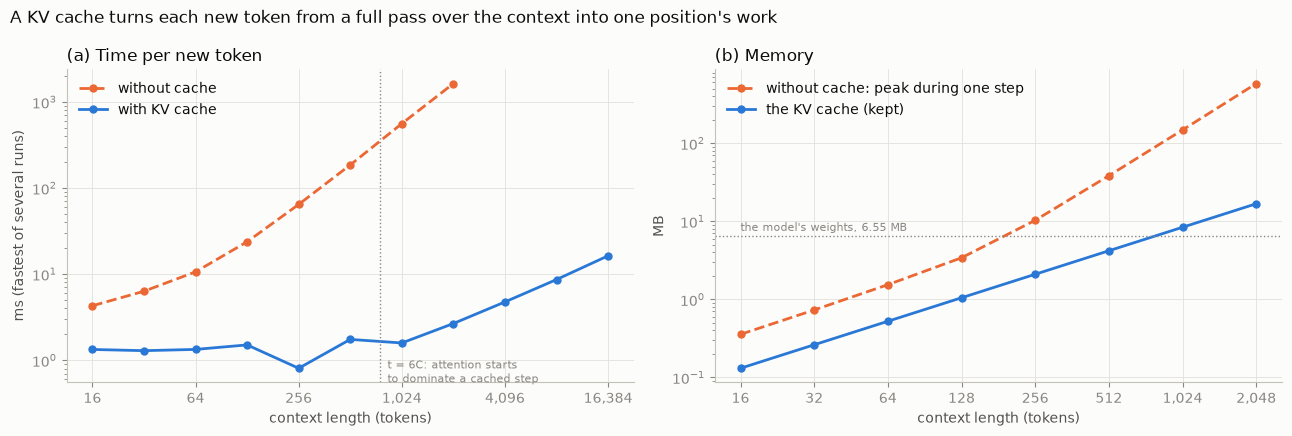

In [9]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.4))
ax1.plot(CTX, [t_unc[t] * 1e3 for t in CTX], "o--", color=SERIES[1], ms=5, label="without cache")
ax1.plot(CTX_CACHED, [t_cac[t] * 1e3 for t in CTX_CACHED], "o-", color=SERIES[0], ms=5, label="with KV cache")
ax1.axvline(6 * cfg128["C"], color=MUTED, ls=":", lw=1)
ax1.text(6 * cfg128["C"] * 1.1, 0.5, "t = 6C: attention's multiply-adds\nmatch the rest of a cached step", color=MUTED, fontsize=8, va="bottom")
ax1.set_title("(a) Time per new token", loc="left")
ax1.set_ylabel("ms (fastest of several runs)")

ax2.plot(CTX, [mem_unc[t] for t in CTX], "o--", color=SERIES[1], ms=5, label="without cache: peak during one step")
ax2.plot(CTX, [mem_cache[t] for t in CTX], "o-", color=SERIES[0], ms=5, label="the KV cache (kept)")
ax2.axhline(model_mb, color=MUTED, ls=":", lw=1)
ax2.text(16, model_mb * 1.15, "the model's weights, 6.55 MB", color=MUTED, fontsize=8)
ax2.set_title("(b) Memory", loc="left")
ax2.set_ylabel("MB")
for ax, xs in ((ax1, CTX_CACHED[::2]), (ax2, CTX)):
    ax.set_xscale("log", base=2)
    ax.set_yscale("log")
    ax.set_xticks(xs, [f"{x:,}" for x in xs])
    ax.set_xlabel("context length (tokens)")
    ax.legend(loc="upper left")
fig.suptitle("A KV cache turns each new token from a full pass over the context into one position's work",
             x=0.01, ha="left", fontsize=12)
plt.tight_layout()
plt.show()

- **The cache grows in a straight line**: doubling the context doubles it. 16.8 MB at 2,048 tokens. It passes the model's own weights (6.55 MB) at 800 tokens.
- **Without the cache, this forward peaks much higher**: the peak during a single step grows with $t^2$ (×4 per doubling at the end), to 581 MB at 2,048 tokens. But that comes from how this forward is written, building the scores for all t × t pairs at once, not from having no cache. Doing attention 128 query rows at a time gives the same logits and peaks at ~61 MB (`run.py` measures both), about 3.6× the cache. FlashAttention takes the same idea further on GPUs.
- **A cached step itself needs almost nothing extra**: 0.35 MB at 2,048.

So for one sequence the cache is still smaller than what a step without it needs, but by ~3.6×, not 35×. The catch is that the cache is *kept*, for every sequence being generated at the same time, while the uncached temporaries only exist during a step. For a server with many users, that's what matters: Step 7.

## Step 7: What this means for real models (calculated)

Our model is tiny, so its cache is too. For real models the same formula, $2 \times L \times d_{kv} \times$ bytes per number, per token and per sequence, gives a very different picture. This is **arithmetic from the published model shapes, not a measurement**. 16-bit numbers (2 bytes), as these models are normally served.

Llama-2-70B uses **grouped-query attention** (GQA): 64 query heads share 8 key/value heads, so its cache stores 8 heads of 128 instead of 64. That is exactly to make this number smaller.

In [10]:
# name, layers, width of what is cached per layer (k or v), bytes per number, params (billions), context
models = [
    ("this GPT (float64)",            4,  128, 8, 0.00082, 128),
    ("GPT-2 small",                   12,  768, 2, 0.124, 1024),
    ("Llama-2-7B",                    32, 4096, 2, 6.7,   4096),
    ("Llama-2-70B (GQA, 8 kv heads)", 80, 1024, 2, 69,    4096),
]
print(f"{'model':30s} {'cache per token':>16s} {'at full context':>22s} {'weights':>10s}")
for name, layers, d_kv, nbytes, params, ctx in models:
    per_tok = 2 * layers * d_kv * nbytes
    full = f"{per_tok * ctx / 1e9:.3f} GB ({ctx:,})"
    print(f"{name:30s} {per_tok / 1e3:13.1f} KB {full:>22s} {params * nbytes:8.3f} GB")

model                           cache per token        at full context    weights
this GPT (float64)                       8.2 KB         0.001 GB (128)    0.007 GB
GPT-2 small                             36.9 KB       0.038 GB (1,024)    0.248 GB
Llama-2-7B                             524.3 KB       2.147 GB (4,096)   13.400 GB
Llama-2-70B (GQA, 8 kv heads)          327.7 KB       1.342 GB (4,096)  138.000 GB


For **Llama-2-7B** the cache is 0.5 MB per token: 2.1 GB for one 4,096-token sequence, 16% of its 13.4 GB of weights. Serving 8 such sequences at once needs 17 GB of cache, more than the model itself. So on a GPU it's often the cache, not the weights, that limits how many users fit at once. That's why **Llama-2-70B** uses GQA: 10× the parameters, but a smaller cache per token than the 7B (0.33 MB against 0.52 MB). For our model the cache is irrelevant, 8 KB per token.

## Summary

**How much faster does generation get, and how much memory does the cache cost?**

- **Speed per new token**: with the cache, roughly flat at ~1–1.5 ms up to ~512 tokens, then growing about linearly (~11–16 ms at 16,384). Without it, from a few ms to ~1.5 s at 2,048 tokens, growing ~3× per doubling of the context by the end. Roughly 600–750× faster at 2,048 (~430–510× against a forward that does attention in blocks); ~50–70× for writing 512 tokens from scratch.
- **The arithmetic explains the shape**: cached work is one position plus attention over $t$ cached keys, and the bend is where that attention catches up with the rest ($t = 6C$). The measured speedup is always smaller than the arithmetic, because a cached step has a fixed overhead.
- **Memory**: the cache grows linearly, 8 KB per token here, and passes the model's own weights at 800 tokens. Without it, this forward's temporary memory grows with $t^2$ (581 MB at 2,048), but that's from building all the scores at once: done in blocks it's ~61 MB, ~3.6× the cache.
- **Real models (calculated)**: Llama-2-7B needs 0.5 MB per token, 2.1 GB per 4k-token sequence, so the cache decides how many sequences fit. GQA (Llama-2-70B) is the standard way to shrink it.

Caveats: one laptop, float64 NumPy on a CPU, not a GPU; single timings can differ by up to 2× between runs (the short cached steps most), so the text gives ranges from two runs; the long contexts use random weights (Step 1 shows the speed is the same).